# T26 · Análise de erros e desempenho por subgrupo

**Objetivo:** ver *onde* o modelo final erra, e em que tipo de paciente ele não deve ser usado sem cautela.
Tudo é calculado na **validação** (o teste foi usado uma única vez, na T23), com o **limiar final da T22**.

> **Modelo e limiar vêm da T23** (`cardio.models.final_model`): XGBoost, conjunto A, limiar 0,36 (o maior limiar com
> recall de pelo menos 0,80 na validação). O modelo salvo em `models/final_model.joblib` foi retreinado com treino
> **mais** validação, então não serve para avaliar na validação: ele já viu esses pacientes e os números ficariam
> otimistas. Por isso este notebook reconstrói a mesma configuração treinada **só no treino**. Se a T23 trocar de
> modelo ou de limiar, basta reexecutar: as constantes são importadas de lá.

**Como ler:** os textos de interpretação são gerados a partir dos dados (nenhum número fixo), como nos
notebooks T03 e T04.

In [1]:
import sys
from pathlib import Path

# Permite rodar o notebook fora do Docker (no Docker o PYTHONPATH já aponta para src/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from importlib import import_module

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score

from cardio.config import FIGURES_DIR, IMC_BINS, IMC_LABELS
from cardio.data.preprocessing import load_splits
from cardio.features.build import categorizar_pressao
from cardio.models.final_model import FEATURE_SET, LIMIAR_FINAL, MODELO_ESCOLHIDO

# cardio.visualization.plots fixa o backend "Agg"; aqui queremos os gráficos dentro do notebook
%matplotlib inline
pd.options.display.float_format = "{:.3f}".format
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Modelo e predições na validação

In [2]:
# Modelo, conjunto de features e limiar da T23/T22 (vêm de cardio.models.final_model).
MODELO_FINAL, CONJUNTO, LIMIAR = MODELO_ESCOLHIDO, FEATURE_SET, LIMIAR_FINAL

X_train, X_val, _, y_train, y_val, _ = load_splits(CONJUNTO, save_ids=False)  # o teste não é usado aqui
modelo = import_module(f"cardio.models.estimators.{MODELO_FINAL}").build_model(X_train).fit(X_train, y_train)  # só treino

proba = pd.Series(modelo.predict_proba(X_val)[:, 1], index=X_val.index)
pred = (proba >= LIMIAR).astype(int).rename("pred")
pred_05 = (proba >= 0.5).astype(int)  # só para comparar com o limiar padrão
print(f"Modelo: {MODELO_FINAL} (conjunto {CONJUNTO}), limiar {LIMIAR} | validação: {len(X_val):,} pacientes".replace(",", "."))
print(f"Recall geral {recall_score(y_val, pred):.3f} | precision {precision_score(y_val, pred):.3f} | F1 {f1_score(y_val, pred):.3f}")
print(f"Com o limiar padrão de 0,5 o recall seria {recall_score(y_val, pred_05):.3f} (precision {precision_score(y_val, pred_05):.3f})")

Modelo: xgb (conjunto A). limiar 0.36 | validação: 10.277 pacientes
Recall geral 0.817 | precision 0.658 | F1 0.729
Com o limiar padrão de 0,5 o recall seria 0.679 (precision 0.747)


## 2. Subgrupos

Quatro cortes, definidos na issue: **sexo**, **faixa de idade** (< 45, 45–55, > 55), **categoria de pressão**
(ACC/AHA, mesma regra do conjunto B) e **faixa de IMC** (faixas da OMS de `config.IMC_BINS`).
Os cortes usam as colunas originais da validação, mesmo quando o modelo não as recebe como feature.

In [3]:
val = X_val.copy()
val["imc"] = val["weight"] / (val["height"] / 100) ** 2
val = categorizar_pressao(val)

grupos = pd.DataFrame(index=val.index)
grupos["Sexo"] = pd.Categorical(np.where(val["sex_male"] == 1, "Homem", "Mulher"), ["Mulher", "Homem"])
grupos["Idade"] = pd.cut(val["age_years"], [0, 45, 55, np.inf], labels=["< 45 anos", "45–55 anos", "> 55 anos"], right=False)
grupos["Pressão"] = pd.Categorical(val["categoria_pressao"], ["Normal", "Elevada", "Hipertensão 1", "Hipertensão 2"])
grupos["IMC"] = pd.cut(val["imc"], IMC_BINS, labels=IMC_LABELS, right=False)


def metricas(mask: pd.Series) -> dict:
    y, p = y_val[mask], pred[mask]
    return {
        "pacientes": int(mask.sum()),
        "% com doença": y.mean(),
        "recall": recall_score(y, p, zero_division=0),
        "precision": precision_score(y, p, zero_division=0),
        "F1": f1_score(y, p, zero_division=0),
        "falsos negativos": int(((y == 1) & (p == 0)).sum()),
    }


linhas = [{"corte": "Todos", "grupo": "Todos os pacientes", **metricas(pd.Series(True, index=val.index))}]
for corte in grupos.columns:
    for grupo in grupos[corte].cat.categories:
        mask = grupos[corte] == grupo
        if mask.any():
            linhas.append({"corte": corte, "grupo": str(grupo), **metricas(mask)})
tabela = pd.DataFrame(linhas)
tabela

,corte,grupo,pacientes,% com doença,recall,precision,F1,falsos negativos
0,Todos,Todos os pacientes,10277,0.495,0.817,0.658,0.729,929
1,Sexo,Mulher,6757,0.493,0.820,0.663,0.733,601
2,Sexo,Homem,3520,0.498,0.813,0.648,0.721,328
3,Idade,< 45 anos,1533,0.299,0.588,0.692,0.636,189
4,Idade,45–55 anos,4104,0.448,0.690,0.684,0.687,570
5,Idade,> 55 anos,4640,0.601,0.939,0.643,0.763,170
6,Pressão,Normal,1487,0.239,0.301,0.525,0.382,249
7,Pressão,Elevada,432,0.343,0.500,0.474,0.487,74
8,Pressão,Hipertensão 1,4868,0.387,0.689,0.511,0.587,586
9,Pressão,Hipertensão 2,3490,0.773,0.993,0.784,0.876,20


## 3. Recall, precision e F1 por subgrupo

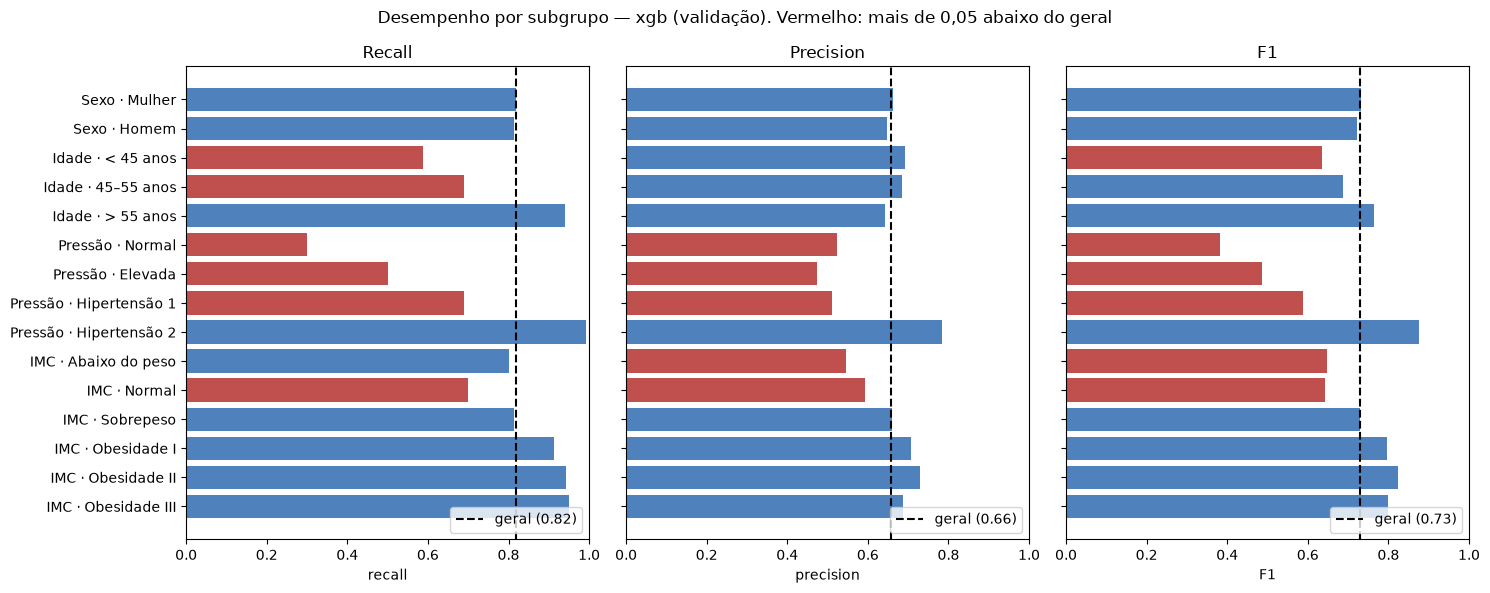

In [4]:
por_grupo = tabela[tabela["corte"] != "Todos"].reset_index(drop=True)
geral = tabela.iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, metrica in zip(axes, ["recall", "precision", "F1"]):
    cores = ["#c0504d" if v < geral[metrica] - 0.05 else "#4f81bd" for v in por_grupo[metrica]]
    ax.barh(por_grupo["corte"] + " · " + por_grupo["grupo"], por_grupo[metrica], color=cores)
    ax.axvline(geral[metrica], color="k", linestyle="--", label=f"geral ({geral[metrica]:.2f})")
    ax.set(title=metrica.capitalize(), xlim=(0, 1), xlabel=metrica)
    ax.legend(loc="lower right")
axes[0].invert_yaxis()
fig.suptitle(f"Desempenho por subgrupo — {MODELO_FINAL} (validação). Vermelho: mais de 0,05 abaixo do geral")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "t26_subgrupos.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
grandes = por_grupo[por_grupo["pacientes"] >= 200].sort_values("recall")
pior, melhor = grandes.iloc[0], grandes.iloc[-1]
abaixo = por_grupo[por_grupo["recall"] < geral["recall"] - 0.05]
mulher = por_grupo[(por_grupo["corte"] == "Sexo") & (por_grupo["grupo"] == "Mulher")].iloc[0]
homem = por_grupo[(por_grupo["corte"] == "Sexo") & (por_grupo["grupo"] == "Homem")].iloc[0]
relevante = "diferença relevante" if abs(mulher["recall"] - homem["recall"]) > 0.05 else "sem diferença relevante, abaixo de 0,05"

print(f"Interpretação: o recall geral é {geral['recall']:.2f}. O pior subgrupo (com 200 pacientes ou mais) é "
      f"«{pior['corte']} · {pior['grupo']}», com recall {pior['recall']:.2f}; o melhor é «{melhor['corte']} · {melhor['grupo']}», "
      f"com {melhor['recall']:.2f}.")
print(f"Sexo: recall de {mulher['recall']:.2f} nas mulheres ({mulher['pacientes'] / geral['pacientes']:.0%} da validação) "
      f"e de {homem['recall']:.2f} nos homens ({relevante}).")
print("Subgrupos com recall mais de 0,05 abaixo do geral: "
      + (", ".join(abaixo["corte"] + " · " + abaixo["grupo"]) or "nenhum") + ".")

Interpretação: o recall geral é 0.82. O pior subgrupo (com 200 pacientes ou mais) é «Pressão · Normal», com recall 0.30; o melhor é «Pressão · Hipertensão 2», com 0.99.
Sexo: recall de 0.82 nas mulheres (66% da validação) e de 0.81 nos homens (sem diferença relevante, abaixo de 0,05).
Subgrupos com recall mais de 0,05 abaixo do geral: Idade · < 45 anos, Idade · 45–55 anos, Pressão · Normal, Pressão · Elevada, Pressão · Hipertensão 1, IMC · Normal.


## 4. Falsos negativos: quem o modelo deixa passar?

Um **falso negativo** é um paciente com doença que o modelo classifica como saudável, o erro mais grave numa
triagem. Comparamos os falsos negativos com os **verdadeiros positivos** (doentes que o modelo achou) e com os
**verdadeiros negativos** para ver se eles *parecem* saudáveis nas variáveis disponíveis: pressão normal e
nenhum fator de risco aparente (colesterol e glicose normais, não fuma, não bebe, ativo e IMC abaixo de 25).

In [6]:
val["sem_fator_risco"] = (
    (val["cholesterol"] == 1) & (val["gluc"] == 1) & (val["smoke"] == 0) & (val["alco"] == 0)
    & (val["active"] == 1) & (val["imc"] < 25)
)
val["pressao_normal"] = val["categoria_pressao"] == "Normal"

fn = (y_val == 1) & (pred == 0)
tp = (y_val == 1) & (pred == 1)
tn = (y_val == 0) & (pred == 0)

colunas = {"age_years": "idade média (anos)", "ap_hi": "sistólica média", "ap_lo": "diastólica média",
           "imc": "IMC médio", "cholesterol": "colesterol médio (1 a 3)",
           "pressao_normal": "% com pressão normal", "sem_fator_risco": "% sem fator de risco aparente"}
comparacao = pd.DataFrame({
    nome: val.loc[mask, list(colunas)].mean().rename(index=colunas)
    for nome, mask in [("Falsos negativos", fn), ("Verdadeiros positivos", tp), ("Saudáveis (VN)", tn)]
})
comparacao

,Falsos negativos,Verdadeiros positivos,Saudáveis (VN)
idade média (anos),50.123,56.044,48.441
sistólica média,115.529,137.513,113.998
diastólica média,75.953,86.241,75.233
IMC médio,25.995,29.069,25.360
colesterol médio (1 a 3),1.114,1.623,1.085
% com pressão normal,0.268,0.026,0.341
% sem fator de risco aparente,0.299,0.109,0.345


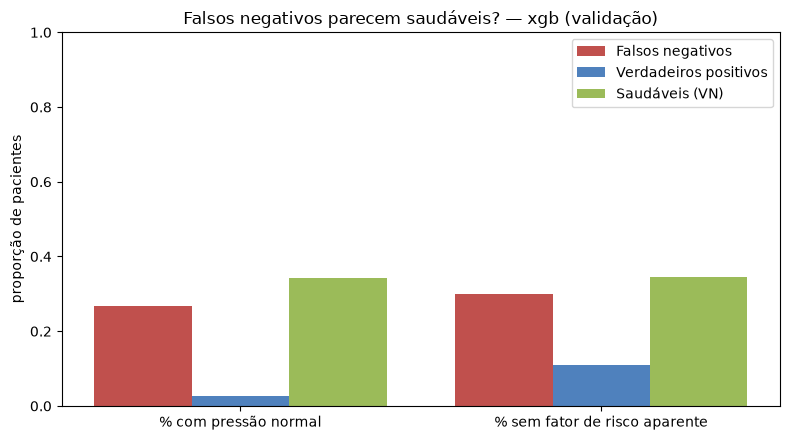

Interpretação: 929 dos 5086 doentes da validação foram deixados passar (18%).
Entre eles, 27% têm pressão normal (contra 3% dos doentes que o modelo achou) e 30% não têm nenhum fator de risco aparente (contra 11%).
Ou seja: o modelo erra principalmente em doentes que, nas variáveis disponíveis, parecem mais saudáveis. É uma limitação da informação (sem exames de imagem, ECG ou histórico familiar), e não só do modelo.


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cats = ["% com pressão normal", "% sem fator de risco aparente"]
largura = 0.27
for i, (col, cor) in enumerate(zip(comparacao.columns, ["#c0504d", "#4f81bd", "#9bbb59"])):
    ax.bar(np.arange(len(cats)) + (i - 1) * largura, comparacao.loc[cats, col], largura, label=col, color=cor)
ax.set(xticks=range(len(cats)), xticklabels=cats, ylabel="proporção de pacientes", ylim=(0, 1),
       title=f"Falsos negativos parecem saudáveis? — {MODELO_FINAL} (validação)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "t26_falsos_negativos.png", dpi=150, bbox_inches="tight")
plt.show()

c = comparacao
doentes = int((y_val == 1).sum())
print(f"Interpretação: {fn.sum()} dos {doentes} doentes da validação foram deixados passar ({fn.sum() / doentes:.0%}).")
print(f"Entre eles, {c.loc['% com pressão normal', 'Falsos negativos']:.0%} têm pressão normal "
      f"(contra {c.loc['% com pressão normal', 'Verdadeiros positivos']:.0%} dos doentes que o modelo achou) e "
      f"{c.loc['% sem fator de risco aparente', 'Falsos negativos']:.0%} não têm nenhum fator de risco aparente "
      f"(contra {c.loc['% sem fator de risco aparente', 'Verdadeiros positivos']:.0%}).")
print("Ou seja: o modelo erra principalmente em doentes que, nas variáveis disponíveis, parecem mais saudáveis. "
      "É uma limitação da informação (sem exames de imagem, ECG ou histórico familiar), e não só do modelo.")

## 5. Conclusão: onde o modelo não deve ser usado sem cautela

In [8]:
top_fn = por_grupo.sort_values("falsos negativos", ascending=False).head(3)
print(f"1. O modelo não substitui a avaliação médica: com recall geral {geral['recall']:.2f}, cerca de "
      f"{1 - geral['recall']:.0%} dos doentes passam despercebidos. Em triagem, um resultado «sem doença» "
      "não exclui o risco.")
print(f"2. Maior cautela com «{pior['corte']} · {pior['grupo']}» (recall {pior['recall']:.2f}, o menor entre os "
      "subgrupos com 200 pacientes ou mais).")
print("3. Pacientes com pressão normal e sem fator de risco aparente: o modelo tende a classificá-los como saudáveis, "
      "mas parte deles tem a doença.")
print("4. Subgrupos com mais falsos negativos em número absoluto: "
      + "; ".join(f"{r['corte']} · {r['grupo']} ({r['falsos negativos']})" for _, r in top_fn.iterrows()) + ".")
fn_05 = int(((y_val == 1) & (pred_05 == 0)).sum())
print(f"5. O limiar {LIMIAR} da T22 reduz os doentes não sinalizados de {fn_05} (limiar 0,5) para {int(fn.sum())}, "
      f"ao custo de mais alarmes falsos ({int(((y_val == 0) & (pred == 1)).sum())} saudáveis encaminhados, contra "
      f"{int(((y_val == 0) & (pred_05 == 1)).sum())} com 0,5).")
print(f"6. Vale para o modelo final da T23 ({MODELO_FINAL}, conjunto {CONJUNTO}) treinado só no treino, na validação. "
      "Se a T23 trocar de modelo ou de limiar, reexecutar o notebook e revisar este texto. "
      "Alimenta a seção de limitações do relatório (T34).")

1. O modelo não substitui a avaliação médica: com recall geral 0.82, cerca de 18% dos doentes passam despercebidos. Em triagem, um resultado «sem doença» não exclui o risco.
2. Maior cautela com «Pressão · Normal» (recall 0.30, o menor entre os subgrupos com 200 pacientes ou mais).
3. Pacientes com pressão normal e sem fator de risco aparente: o modelo tende a classificá-los como saudáveis, mas parte deles tem a doença.
4. Subgrupos com mais falsos negativos em número absoluto: Sexo · Mulher (601); Pressão · Hipertensão 1 (586); Idade · 45–55 anos (570).
5. O limiar 0.36 da T22 reduz os doentes não sinalizados de 1635 (limiar 0,5) para 929, ao custo de mais alarmes falsos (2160 saudáveis encaminhados, contra 1171 com 0,5).
6. Vale para o modelo final da T23 (xgb, conjunto A) treinado só no treino, na validação. Se a T23 trocar de modelo ou de limiar, reexecutar o notebook e revisar este texto. Alimenta a seção de limitações do relatório (T34).
